# Car Dominance Analysis Using Street View Imagery (SVI)

**Overview**: In this script, we analyze car dominance in large housing estates using visual indices derived from segmented Street View Images (SVI) obtained from Mapillary. The focus is on quantifying and visualizing car-related presence on *inner streets* across three case study cities.

**Inputs**: Preprocessed visual indices provided by Winston Yap (NUS), based on segmentation of Mapillary SVI for each case study site in Sofia, Buldaria, Riga, Latvia, and Budapest, Hungary.

**Outputs**: Visualizations of car dominance across inner streets in each city. <br>
(Figures used in the journal article *Car dominance as a challenge for neighbourhoods: A mixed-method assessment of public open space in large housing estates*)

**Start Date**: *May 2, 2025*<br>
**Author**: *Kanaha Shoji*

In [ ]:
# Import necessary libraries and functions
import osmnx as ox
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import numpy as np
import warnings
import os
from shapely.validation import make_valid
from matplotlib.lines import Line2D
import seaborn as sns
import matplotlib.colors as colors
import matplotlib.cm as cm
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.colors as mcolors
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.patches as mpatches
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from matplotlib.colors import to_rgb, to_hex

In [2]:
np.random.seed(1234)  # for reproducibility

In [ ]:
# Set base directory (Adjust this path as needed)
base_dir = '/Users/shoji/Library/CloudStorage/OneDrive-epfl.ch/2024_DUT_Driving_Urban_Transitions/2025_07_Urban_Planning_jorunal_paper'
# Set data directory for Mapillary images
geodata_dir = '/Users/shoji/Library/CloudStorage/OneDrive-SharedLibraries-RīgasTehniskāUniversitāte/15minESTATES_O365G - Documents/WP4/01_Geodata/'
svi_dir = os.path.join(geodata_dir, 'Mapillary_segmentedStreetViewImages/svis/')

In [4]:
sofia_svi = gpd.read_file(os.path.join(svi_dir,'bulgaria.geojson')).to_crs("EPSG:4326")
riga_svi = gpd.read_file(os.path.join(svi_dir,'latvia.geojson')).to_crs("EPSG:4326")
budapest_svi = gpd.read_file(os.path.join(svi_dir,'hungary.geojson')).to_crs("EPSG:4326")

In [5]:
sofia_site = gpd.read_file(os.path.join(geodata_dir, 'Sofia/01_LHE_geometry/bg_Mladost_4326.gpkg')).to_crs("EPSG:4326")
riga_site = gpd.read_file(os.path.join(geodata_dir, 'Riga/01_LHE_geometry/lv_Riga_Ziepnikkalns_4326.gpkg')).to_crs("EPSG:4326")
budapest_site = gpd.read_file(os.path.join(geodata_dir, 'Budapest/01_LHE_geometry/hu_Pesterzsébet_4326.gpkg')).to_crs("EPSG:4326")

In [6]:
# Print the number of images in each city
print(f"Sofia: {len(sofia_svi)} images")
print(f"Riga: {len(riga_svi)} images")
print(f"Budapest: {len(budapest_svi)} images")

Sofia: 17293 images
Riga: 33625 images
Budapest: 12267 images


NOTES:<br>
in Winston's paper ("A Global Feature-Rich Network Dataset of Cities and Dashboard for Comprehensive Urban Analyses" (2023) https://doi.org/10.1038/s41597-023-02578-1), they kept the images with
- image orientation angle (excluding those with more than 20 degrees),
- time of day (only keeping photos between 9 am and 5 pm), 
- visual complexity (keeping only those above 1.0)

--> In our case, we don't have orientation angle and time of day info but will filter based on visual complexity

In [7]:
sofia_svi_original = sofia_svi.copy()
sofia_svi = sofia_svi[sofia_svi['Visual Complexity'] > 1]

### Extract street types from OSM for each case study site

In [8]:
# Extract street types from OSM for Sofia
# Extract the 'highway' features for Sofia from OSM
sofia_union = sofia_site.union_all()
sofia_union_valid = make_valid(sofia_union)
sofia_streets = ox.features_from_polygon(
    sofia_union_valid, 
    tags={'highway': True}
).to_crs("EPSG:4326")

# Keep only LineString and MultiLineString geometries
sofia_streets = sofia_streets[
    sofia_streets.geometry.type.isin(['LineString', 'MultiLineString'])
]

# sofia_streets.plot()

In [9]:
# Keep only the 'id', 'geometry', and 'highway' columns
sofia_streets = sofia_streets.reset_index() 
sofia_streets = sofia_streets[['id', 'geometry', 'highway']]
# print(sofia_streets.head())

# Filter out to get streets within the site
sofia_streets_in_site = sofia_streets[sofia_streets.within(sofia_site.union_all())]
# sofia_streets_in_site.plot()

In [10]:
# Extract street types from OSM for Riga
# Extract the 'highway' features for Riga from OSM
riga_union = riga_site.union_all()
riga_union_valid = make_valid(riga_union)
riga_streets = ox.features_from_polygon(
    riga_union_valid, 
    tags={'highway': True}
).to_crs("EPSG:4326")

# Keep only LineString and MultiLineString geometries
riga_streets = riga_streets[
    riga_streets.geometry.type.isin(['LineString', 'MultiLineString'])
]

# riga_streets.plot()

In [11]:
# Keep only the 'id', 'geometry', and 'highway' columns
riga_streets = riga_streets.reset_index() 
riga_streets = riga_streets[['id', 'geometry', 'highway']]
# print(riga_streets.head())

# Filter out to get streets within the site
riga_streets_in_site = riga_streets[riga_streets.within(riga_site.union_all())]
# riga_streets_in_site.plot()

In [12]:
# Extract street types from OSM for Budapest

# Combine all geometries into one (MultiPolygon or Polygon)
budapest_union = budapest_site.union_all()
budapest_union_valid = make_valid(budapest_union)

budapest_streets = ox.features_from_polygon(
    budapest_union_valid, 
    tags={'highway': True}
).to_crs("EPSG:4326")

# Keep only LineString and MultiLineString geometries
budapest_streets = budapest_streets[
    budapest_streets.geometry.type.isin(['LineString', 'MultiLineString'])
]
# budapest_streets.plot()

In [13]:
# Keep only the 'id', 'geometry', and 'highway' columns
budapest_streets = budapest_streets.reset_index() 
budapest_streets = budapest_streets[['id', 'geometry', 'highway']]
# print(budapest_streets.head())

# Filter out to get streets within the site
budapest_streets_in_site = budapest_streets[budapest_streets.within(budapest_site.union_all())]
# budapest_streets_in_site.plot()

In [14]:
# Create color map for highway types to cover all the available types among the three cities
highway_types = np.unique(np.concatenate([
    sofia_streets_in_site['highway'].unique(),
    riga_streets_in_site['highway'].unique(),
    budapest_streets_in_site['highway'].unique()
]))
# Create a color map for the highway types
highway_colors = plt.cm.tab20.colors
highway_color_map = {ht: highway_colors[i % len(highway_colors)] for i, ht in enumerate(highway_types)}


In [42]:
# highway_types

| **Category**                        | **Description**                                                                 | **OSM `highway` Tags**                                                                                     |
| ----------------------------------- | ------------------------------------------------------------------------------- | ---------------------------------------------------------------------------------------------------------- |
| **Pedestrian-Oriented**             | Prioritizes walking; minimal or no vehicle presence                             | `'footway'`, `'pedestrian'`, `'steps'`, `'platform'`, `'path'`  |
| **Residential / Slow-Speed Mixed**  | Within housing areas; designed for low-speed, often shared with pedestrians     | `'residential'`, `'living_street'`                                                                         |
| **Cycle-Focused**                   | Dedicated bike paths                                                            | `'cycleway'`                                                                                               |
| **Shared Access / Local Mixed-Use** | Internal estate roads, often with car and pedestrian use; parking often present | `'service'`, `'tertiary_link'`                                                                             |
| **Motor Traffic-Oriented**          | Streets functionally dominated by vehicular traffic and/or on-street parking    | `'tertiary'`, `'primary'`, `'primary_link'`, `'secondary'`, `'trunk'`, `'trunk_link'`                      |
| **Undefined / Transitional**        | Poorly defined or under development; not clearly designed for any one use       | `'construction'`, `'unclassified'`, `'proposed'`, `'track'`                                                |


In [16]:
# Define the functional categories mapping
functional_category_map = {
    'footway': 'Pedestrian-Oriented',
    'pedestrian': 'Pedestrian-Oriented',
    'steps': 'Pedestrian-Oriented',
    'platform': 'Pedestrian-Oriented',
    'path': 'Pedestrian-Oriented',
    
    'residential': 'Residential / Slow-Speed Mixed',
    'living_street': 'Residential / Slow-Speed Mixed',
    
    'cycleway': 'Cycle-Focused',
    
    'service': 'Shared Access / Local Mixed-Use',
    'tertiary_link': 'Shared Access / Local Mixed-Use',
    
    'tertiary': 'Motor Traffic-Oriented',
    'primary': 'Motor Traffic-Oriented',
    'primary_link': 'Motor Traffic-Oriented',
    'secondary': 'Motor Traffic-Oriented',
    'trunk': 'Motor Traffic-Oriented',
    'trunk_link': 'Motor Traffic-Oriented',
    
    'construction': 'Undefined / Transitional',
    'unclassified': 'Undefined / Transitional',
    'proposed': 'Undefined / Transitional',
    'track': 'Undefined / Transitional'
}

In [17]:
# Add a new column for the functional category
riga_streets_in_site = riga_streets_in_site.copy()
riga_streets_in_site['functional_category'] = riga_streets_in_site['highway'].map(functional_category_map)
budapest_streets_in_site = budapest_streets_in_site.copy()
budapest_streets_in_site['functional_category'] = budapest_streets_in_site['highway'].map(functional_category_map)
sofia_streets_in_site = sofia_streets_in_site.copy()
sofia_streets_in_site['functional_category'] = sofia_streets_in_site['highway'].map(functional_category_map)


In [18]:
clarity_ranking = ["Residential / Slow-Speed Mixed", "Shared Access / Local Mixed-Use",
                    "Motor Traffic-Oriented","Pedestrian-Oriented", "Cycle-Focused", 
                     "Undefined / Transitional"]

In [19]:
# Create color map for categories
categories = sorted(set(functional_category_map.values()))
category_colors = plt.cm.Set2.colors  # or use tab10, tab20, etc.

tol_colors = [
    "#332288",  # navy
    "#88CCEE",  # sky blue
    # "#44AA99",  # teal
    "#117733",  # green
    "#999933",  # olive
    "#DDCC77",  # sand
    "#CC6677",  # red
    "#882255",  # wine
    "#AA4499"   # purple
]

category_color_map = dict(zip(clarity_ranking, tol_colors))

In [20]:
def plot_street_cat(ax=None, streets_in_site=None):# Plot using functional category
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))
        fig.patch.set_alpha(0.0)
    ax.set_facecolor('none')

    streets_in_site.plot(
        ax=ax,
        color=streets_in_site['functional_category'].map(category_color_map),
        linewidth=1.5, alpha=0.8)

    # ax.set_title("Riga: Streets by Functional Category")
    ax.axis('off')
    if ax is None:
        plt.show()

In [21]:
legend_handles = [
    mpatches.Patch(color=category_color_map[cat], label=cat)
    for cat in clarity_ranking
]

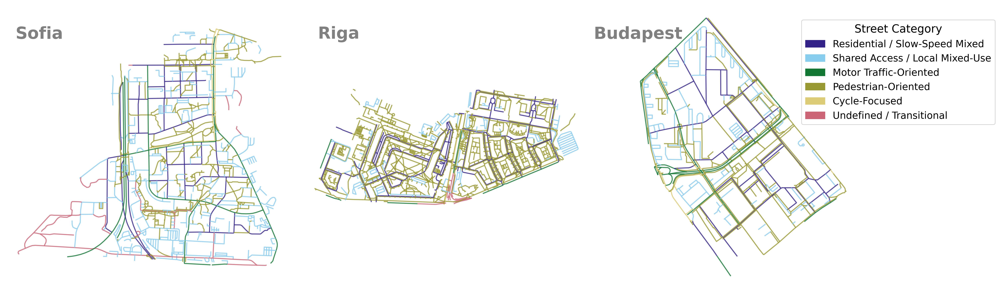

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=300)

plot_street_cat(streets_in_site=sofia_streets_in_site, ax=axes[0]) 
plot_street_cat(streets_in_site=riga_streets_in_site,ax=axes[1]) 
plot_street_cat(streets_in_site=budapest_streets_in_site, ax=axes[2]) # no_title=True,

titles = ['Sofia', 'Riga', 'Budapest']
for i, title in enumerate(titles):
    x = (i+ 0.5) / 3 -0.12 # centers over each subplot (since 3 total)
    fig.text(x, 0.85, title, ha='center', va='bottom',
             fontsize=24, fontweight='bold', color='grey')
    
# Add shared legend at the far right
fig.legend(
    handles=legend_handles, title="Street Category",
    loc='center left', bbox_to_anchor=(0.89, 0.75),
    fontsize=14, title_fontsize=16)

plt.tight_layout()
plt.show()

### Assign street functional category to SVIs

In [23]:
# Combined approach (Buffer but keep nearest)

projected_crs = "EPSG:32635"
# 6. For SVI points with multiple buffer matches, keep only the one matching nearest street
def keep_best(group):
    # If any buffer match is the nearest, keep it; else keep the first
    match = group[group['buffer_street_idx'] == group['nearest_street_idx']]
    if not match.empty:
        return match.iloc[[0]]
    else:
        return group.iloc[[0]]
    
def assign_category(category = 'functional_category', streets_in_site = None, site_svi = None):
    # 1. Project to projected CRS
    streets_proj = streets_in_site.to_crs(projected_crs)
    svi_proj = site_svi.to_crs(projected_crs)

    # 2. Nearest street for each SVI
    svi_nearest = gpd.sjoin_nearest(
        svi_proj, 
        streets_proj[[category, 'geometry']], 
        how='left', 
        distance_col='dist_to_street')
    svi_nearest = svi_nearest.rename(columns={category: f'nearest_{category}'})
    svi_nearest['nearest_street_idx'] = svi_nearest['index_right']

    # 3. Buffer the street lines
    buffered_streets_proj = streets_proj.copy()
    buffered_streets_proj['geometry'] = buffered_streets_proj.geometry.buffer(15) # buffer in meters

    # 4. Buffer join (may result in multiple matches)
    svi_buffer = gpd.sjoin(
        svi_proj, 
        buffered_streets_proj[[category, 'geometry']], 
        how='left', 
        predicate='within')
    svi_buffer['buffer_street_idx'] = svi_buffer['index_right']

    # 5. Merge nearest info into buffer join
    svi_buffer = svi_buffer.merge(
        svi_nearest[[f'nearest_{category}', 'nearest_street_idx']], 
        left_index=True, right_index=True, how='left')
    # 6. For SVI points with multiple buffer matches, keep only the one matching nearest street
    svi_buffer_best = svi_buffer.groupby(svi_buffer.index).apply(keep_best).reset_index(drop=True)

    # 7. Reproject back to WGS84
    site_svi_with_category = svi_buffer_best.to_crs("EPSG:4326")
    site_svi_with_category.drop(columns=[f'nearest_{category}', 'buffer_street_idx', 'index_right'], inplace=True) # 'nearest_street_idx',
    return site_svi_with_category

In [24]:
riga_svi_with_category = assign_category(category='functional_category', 
    streets_in_site=riga_streets_in_site, 
    site_svi=riga_svi)
budapest_svi_with_category = assign_category(category='functional_category', 
    streets_in_site=budapest_streets_in_site, 
    site_svi=budapest_svi)
sofia_svi_with_category = assign_category(category='functional_category', 
    streets_in_site=sofia_streets_in_site, 
    site_svi=sofia_svi)

In [25]:
def plot_svi_cat_with_streets(site=None,
                              streets_in_site =None, site_svi_with_category = None, 
                              color_map = category_color_map, categories = categories, legend=True, no_title=False, ax=None):
    # Create a new figure and axis for plotting
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7), dpi=300)
        fig.patch.set_alpha(0.0)
    ax.set_facecolor('none')

    # Plot streets colored by categories
    streets_in_site.plot(
        ax=ax, 
        color=streets_in_site['functional_category'].map(color_map), 
        linewidth=1, alpha=0.6, label='Streets'
    )
    # Plot SVI points colored by assigned categories
    site_svi_with_category.dropna(subset=['functional_category']).plot(
        ax=ax,
        color=site_svi_with_category.dropna(subset=['functional_category'])['functional_category'].map(color_map),
        markersize=4, alpha=0.3, marker='o', label='SVI'
    )

    # Add legend for categories
    if legend:
        legend_elements = [Line2D([0], [0], color=color_map[cat], lw=4, label=cat) for cat in categories]
        ax.legend(handles=legend_elements, title="functional_category", loc='upper left')

    if no_title:
        ax.set_title("")
    else:
         ax.set_title(site, fontdict={'fontsize': 24, 'fontweight': 'bold', 'color': 'grey'})#: Streets and SVI Points by fclass using buffered streets and keeping nearest")
    ax.axis('off')
    if ax is None:
        plt.show()

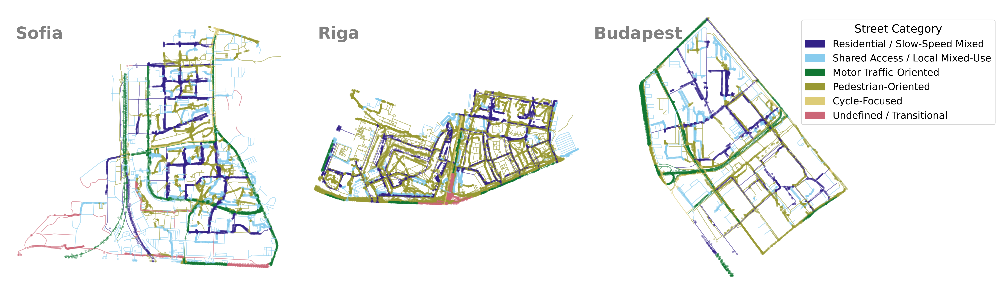

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=300)

plot_svi_cat_with_streets(site='Sofia', 
    streets_in_site=sofia_streets_in_site, 
    site_svi_with_category=sofia_svi_with_category, 
    legend=False,no_title=True, ax=axes[0]) 

plot_svi_cat_with_streets(site='Riga',
    streets_in_site=riga_streets_in_site, 
    site_svi_with_category=riga_svi_with_category, 
    legend=False, no_title=True,ax=axes[1]) 

plot_svi_cat_with_streets(site='Budapest',
    streets_in_site=budapest_streets_in_site,
    site_svi_with_category=budapest_svi_with_category, 
    legend=False, no_title=True,ax=axes[2]) # no_title=True,

titles = ['Sofia', 'Riga', 'Budapest']
for i, title in enumerate(titles):
    x = (i+ 0.5) / 3 -0.12 # centers over each subplot (since 3 total)
    fig.text(x, 0.85, title, ha='center', va='bottom',
             fontsize=24, fontweight='bold', color='grey')
    
# Add shared legend at the far right
fig.legend(
    handles=legend_handles, title="Street Category",
    loc='center left', bbox_to_anchor=(0.89, 0.75),
    fontsize=14, title_fontsize=16)

plt.tight_layout()
plt.show()

In [27]:
# Show the SVI points without functional category with number rounded to 2 decimal places
print("Riga SVI without functional category (%):", 
      round(len(riga_svi_with_category[riga_svi_with_category['functional_category'].isna()]) / len(riga_svi) * 100,2))
print("Budapest SVI without functional category (%):",
      round(len(budapest_svi_with_category[budapest_svi_with_category['functional_category'].isna()]) / len(budapest_svi) * 100,2))
print("Sofia SVI without functional category (%):",
      round(len(sofia_svi_with_category[sofia_svi_with_category['functional_category'].isna()]) / len(sofia_svi) * 100, 2))
# Print total number of SVI points in each city
print("Riga SVI total:", len(riga_svi))
print("Budapest SVI total:", len(budapest_svi))
print("Sofia SVI total:", len(sofia_svi))

Riga SVI without functional category (%): 4.73
Budapest SVI without functional category (%): 9.72
Sofia SVI without functional category (%): 8.38
Riga SVI total: 33625
Budapest SVI total: 12267
Sofia SVI total: 17199


In [28]:
# Show the SVI points without functional category on the map
def plot_svi_without_category(site=None,site_streets_in_site=None, site_svi_with_category = None,
                              color_map=category_color_map, no_legend=False,no_title=False, ax=None):
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))
        fig.patch.set_alpha(0.0)
    ax.set_facecolor('none')
    # Plot streets colored by categories
    site_streets_in_site.plot(
        ax=ax, 
        color=site_streets_in_site['functional_category'].map(color_map), 
        linewidth=1, alpha=0.6, label='Streets'
    )
    # Plot SVI points without functional category
    site_svi_with_category[site_svi_with_category['functional_category'].isna()].plot(
        ax=ax,
        color='grey',  # Use a distinct color for points without category
        markersize=4, alpha=0.3, marker='o', label='SVI without functional category'
    )
    # Add legend for categories
    legend_elements = [Line2D([0], [0], color=color_map[cat], lw=4, label=cat) for cat in categories]
    ax.legend(handles=legend_elements, title="Category", loc=(0.99, 0.1), frameon=True)
    if no_legend:
        ax.get_legend().remove()
    # legend_elements = [Line2D([1], [0], color='grey', lw=4, label='SVI without functional category')]
    # ax.legend(handles=legend_elements, title="test", loc='upper left')
    if no_title:
        ax.set_title("")
    else:
        ax.set_title(f"{site}: SVI Points without Functional Category")
    ax.axis('off')
    if ax is None:
        plt.show()

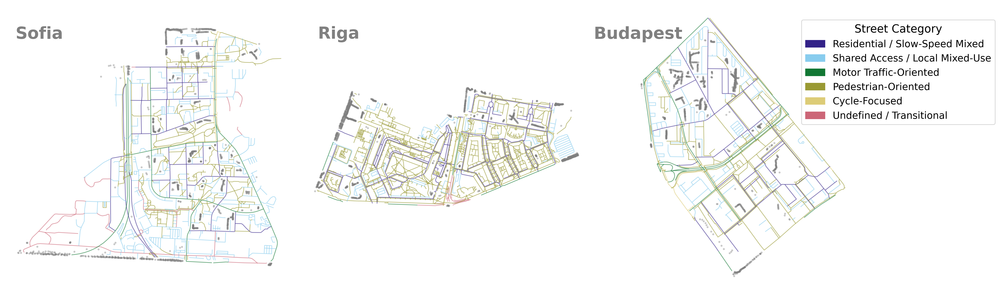

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), dpi=300)

plot_svi_without_category(site='Sofia',no_title=True,
    site_streets_in_site=sofia_streets_in_site, 
    site_svi_with_category=sofia_svi_with_category, no_legend=True, ax=axes[0])
plot_svi_without_category(site='Riga',no_title=True,
    site_streets_in_site=riga_streets_in_site, 
    site_svi_with_category=riga_svi_with_category, no_legend=True, ax=axes[1])
plot_svi_without_category(site='Budapest',no_title=True,
    site_streets_in_site=budapest_streets_in_site,
    site_svi_with_category=budapest_svi_with_category, no_legend=True, ax=axes[2])
titles = ['Sofia', 'Riga', 'Budapest']

for i, title in enumerate(titles):
    x = (i+ 0.5) / 3 -0.12 # centers over each subplot (since 3 total)
    fig.text(x, 0.85, title, ha='center', va='bottom',
             fontsize=24, fontweight='bold', color='grey')
# Add shared legend at the far right
fig.legend(
    handles=legend_handles, title="Street Category",
    loc='center left', bbox_to_anchor=(0.89, 0.75),
    fontsize=14, title_fontsize=16)

plt.tight_layout()
plt.show()

In [31]:
custom_palette = {
    'Cycle-Focused': (0.4, 0.76, 0.65),
    'Motor Traffic-Oriented': (0.988, 0.553, 0.384),
    'Pedestrian-Oriented': (0.553, 0.627, 0.796),
    'Residential / Slow-Speed Mixed': (0.906, 0.541, 0.765),
    'Shared Access / Local Mixed-Use': (0.651, 0.847, 0.329),
    'Undefined / Transitional': (1.0, 0.851, 0.184)
}

In [32]:
def letter_value_plot(site_svi_with_category=None, order=clarity_ranking, color_map=category_color_map, no_lables=False, ax=None):

    # Filter to only present categories
    present_categories = [cat for cat in order if cat in site_svi_with_category["functional_category"].unique()]
    if ax is None:
        # plt.figure(figsize=(8, len(present_categories) * 0.45))
        fig, ax = plt.subplots(figsize=(8, 2))

    sns.set_theme(style="whitegrid")

    ax = sns.boxenplot(
        data=site_svi_with_category,
        x="Car View",
        y="functional_category",
        palette=color_map,
        hue="functional_category",
        order=present_categories,  # use filtered list
        width_method="linear",
        linecolor="white",
        legend=False,
        alpha=0.7,
        ax=ax,
        width=0.8,
        flier_kws={
            "marker": "o",
            "alpha": 0.6,
        })

    grouped_means = site_svi_with_category.groupby("functional_category")["Car View"].mean()
    for i, category in enumerate(present_categories):
        mean_val = grouped_means[category]
        ax.plot(mean_val, i, 'D', color='black', markersize=3)
        ax.text(mean_val, i - 0.3, f"{mean_val:.2f}", va='center', fontsize=12, color='black')

    for i, category in enumerate(present_categories):
        median_val = site_svi_with_category[
            site_svi_with_category["functional_category"] == category
        ]["Car View"].median()
        ax.plot([median_val, median_val], [i - 0.36, i + 0.36], color="black", linewidth=1)

    if no_lables:
        ax.set_xlabel("")
        ax.set_ylabel("")
    else:
        ax.set_xlabel("Car View Score", fontsize=12)
        ax.set_ylabel("Street Category", fontsize=12)
    ax.tick_params(axis='both', labelsize=12)
    # Set x axis limits
    ax.set_xlim(0, 0.8)  # Adjust as needed based on your data range
    plt.gcf().patch.set_alpha(0)
    plt.gca().patch.set_alpha(0)
    sns.despine(left=True, bottom=True)

    if ax is None:
        plt.tight_layout()
        plt.show()


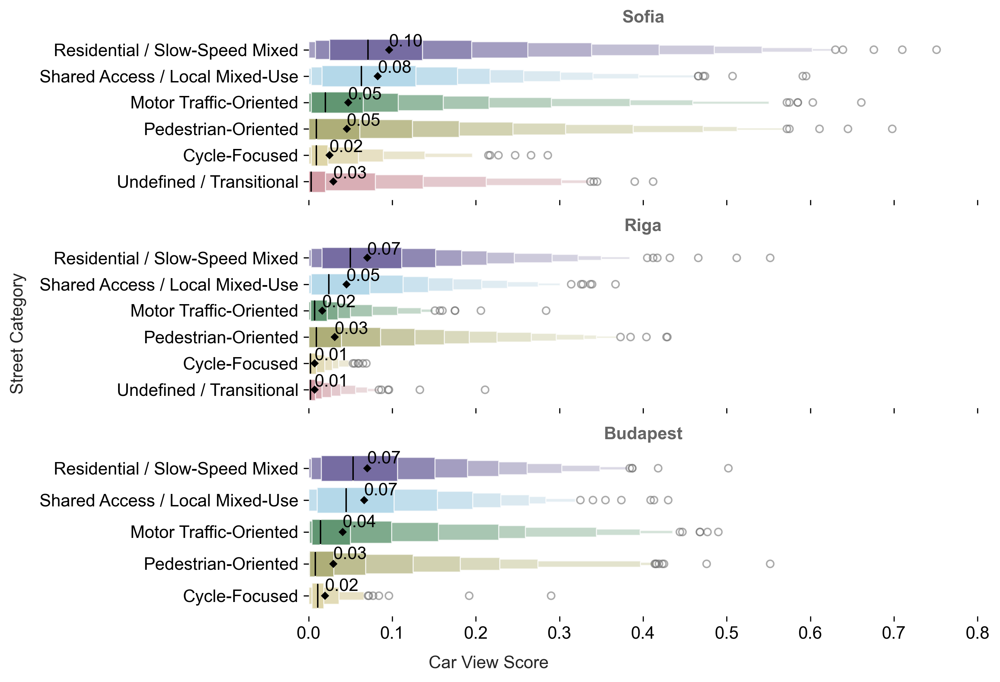

In [33]:
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, dpi=300)
# Set the figure background to transparent
fig.patch.set_alpha(0.0)
# Set the axes background to transparent
for ax in axes:
    ax.set_facecolor('none')

# Plot each dataset
letter_value_plot(site_svi_with_category=sofia_svi_with_category, no_lables=True, ax=axes[0])
axes[0].set_title("Sofia", fontsize=12,color = "black",fontweight='bold', alpha=0.6)

letter_value_plot(site_svi_with_category=riga_svi_with_category, no_lables=True, ax=axes[1])
axes[1].set_title("Riga", fontsize=12, color = "black",fontweight='bold', alpha=0.6)

letter_value_plot(site_svi_with_category=budapest_svi_with_category, no_lables=True, ax=axes[2])
axes[2].set_title("Budapest", fontsize=12,color = "black",fontweight='bold', alpha=0.6)

# Global x and y labels
fig.text(0.5, 0.04, 'Car View Score', ha='center', fontsize=12)
fig.text(0.04, 0.5, 'Street Category', va='center', rotation='vertical', fontsize=12)

plt.tight_layout(rect=[0.05, 0.05, 1, 0.97])  # Leave room for labels
plt.show()

In [34]:
# Measure length of each street segment in the streets_in_site GeoDataFrame
# Use GeoSeries.to_crs() to ensure the length is calculated in meters
sofia_streets_in_site['length'] = sofia_streets_in_site.geometry.to_crs("EPSG:32635").length
# Calculate the total length of each functional category
length_by_category = sofia_streets_in_site.groupby('functional_category')['length'].sum().sort_values(ascending=False)

In [36]:
# Use a fixed color per bin
bins = [-0.001, 0, 0.01, 0.05, 0.10,0.15 ,1.0]
labels = ['0', '0-0.01', '0.01-0.05', '0.05-0.1', '0.1-0.15','0.15-1']
bin_order = ['0', '0-0.01', '0.01-0.05', '0.05-0.1', '0.1-0.15', '0.15-1']

n = len(labels)
bin_colors = {
    label: mcolors.to_hex(plt.colormaps['coolwarm'](i / (n - 1)))
    for i, label in enumerate(labels)}

ordered_categories = [
    'Residential / Slow-Speed Mixed',
    'Shared Access / Local Mixed-Use',
    'Pedestrian-Oriented',
    'Motor Traffic-Oriented',
    'Cycle-Focused'
]

In [37]:
def darken_color(color, factor=0.6): # Return a darker shade of the given color
    r, g, b = to_rgb(color)
    return to_hex((r * factor, g * factor, b * factor))

In [38]:
def stacked_bar_plot(site_svi_with_category =None,
                     category='functional_category',bins = bins, labels = labels,
                     bin_order = bin_order, bin_colors=bin_colors, ordered_categories=ordered_categories,
                     site =None, label_factor=0.6, no_legend=False, no_title=False, no_y_labels=False,
                     figsize=(12, 3), ax=None):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        site_svi_with_category = site_svi_with_category.copy()
        site_svi_with_category['Car_View_bin'] = pd.cut(
        site_svi_with_category['Car View'],
        bins=bins,
        labels=labels,
        include_lowest=True)
        df = site_svi_with_category.dropna(subset=['Car View'])
        grouped = df.groupby([category, 'Car_View_bin'], observed=False).size().reset_index(name='count')
        # Step 4: Total points per category (for normalization)
        total_points = grouped.groupby(category)['count'].sum().reset_index(name='total_count')
        grouped = grouped.merge(total_points, on=category)
        grouped['proportion'] = grouped['count'] / grouped['total_count']

        pivot = grouped.pivot(index='functional_category', columns='Car_View_bin', values='proportion').fillna(0)
        # Ensure pivot columns are in the right bin order
        pivot = pivot[bin_order]
        pivot = pivot.loc[ordered_categories[::-1]]  # reverse the list

        # Create the plot
        if ax is None:
            fig, ax = plt.subplots(figsize=figsize)
            fig.patch.set_alpha(0.0)
        ax.set_facecolor('none')
        bottom = np.zeros(len(pivot))
        bin_order = bin_order[::-1]

        for bin_label in bin_order:
            values = pivot[bin_label].values
            color = bin_colors[bin_label]
            label_color = darken_color(color, label_factor)

            bars = ax.barh(pivot.index, values,
                left=bottom, color=color,
                alpha=0.5,
                edgecolor='white',
                label=bin_label
            )

            for i, (v, b) in enumerate(zip(values, bottom)):
                if v > 0.01:
                    ax.text(
                        b + v / 2, i,
                        f"{v * 100:.0f}",#%
                        ha='center', va='center',
                        fontsize=16,
                        color=label_color,
                        fontweight='bold')

            bottom += values  # ← Important! Update bottom for stacking

        # Styling
        ax.set_xlim(0, 1)
        ax.set_xlabel("Proportion of Car View Points", fontsize=14)
        if no_title:
            ax.set_title('')
        else:
            ax.set_title(f"{site}: Normalized Car_View Distribution per Functional Category")
        ax.legend(title="Car View Bin", bbox_to_anchor=(1.05, 1), loc='upper left')
        if no_legend:
            ax.get_legend().remove()
        
        # Format x-axis tick labels as percentages
        ax.set_xticklabels([f"{int(x * 100)}%" for x in ax.get_xticks()], fontsize=14)

        # Optionally format y-axis labels
        if no_y_labels:
            ax.set_yticklabels([])
        else:
            ax.set_yticklabels([label.title() for label in pivot.index], fontsize=14)
        ax.tick_params(axis='x', which='both', bottom=True, labelbottom=True, color = 'grey')

        
        # Remove top, right, and left borders (spines)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        ax.spines['left'].set_visible(False)
        # Optional: Customize the remaining x-axis spine
        ax.spines['bottom'].set_color('gray')    # or any color you want
        ax.spines['bottom'].set_linewidth(0.5)   # adjust thickness
        ax.tick_params(left=False)      # remove y ticks
        ax.grid(False)                  # remove gridlines
        plt.tight_layout()
        if ax is None:
            plt.show()

In [39]:
def plot_street_median_svi(site_svi_with_category=None, site_streets_in_site=None, site=None,
                           log_transform=False, no95th=False, define_bins=False,
                           filter_functional_categories=None, differentiate_streets=False,
                           shared_extent=None, no_legend=False, no_title=False, ax=None, set_labels=False):

    svi = site_svi_with_category.copy()

    if differentiate_streets:
        # Mark which points are in target category
        svi['is_target_category'] = svi['functional_category'].isin(filter_functional_categories)

        # Compute score for all streets
        street_scores = svi.groupby('nearest_street_idx')['Car View'].median().reset_index()
        street_scores.columns = ['street_idx', 'car_view_score']

        # Flag whether each street has *any* SVI in target category
        category_flags = svi.groupby('nearest_street_idx')['is_target_category'].any().reset_index()
        category_flags.columns = ['street_idx', 'in_target_category']

        street_scores = street_scores.merge(category_flags, on='street_idx', how='left')
        street_scores['in_target_category'] = street_scores['in_target_category'].fillna(False)

    else:
        # Only use data in selected categories
        if filter_functional_categories is not None:
            svi = svi[svi['functional_category'].isin(filter_functional_categories)]
        street_scores = svi.groupby('nearest_street_idx')['Car View'].median().reset_index()
        street_scores.columns = ['street_idx', 'car_view_score']

    # Prepare base streets
    streets_proj = site_streets_in_site.to_crs("EPSG:32635").copy()
    if 'street_idx' in streets_proj.columns:
        streets_proj = streets_proj.drop(columns='street_idx')
    streets_proj = streets_proj.reset_index().rename(columns={'index': 'street_idx'})
    streets_proj = streets_proj.loc[:, ~streets_proj.columns.duplicated()]
    streets_proj = streets_proj.merge(street_scores, on='street_idx', how='left')

    # Log transform
    streets_proj['log_car_view'] = np.log1p(streets_proj['car_view_score'])

    # Plot setup
    if ax is None:
        fig, ax = plt.subplots(figsize=(7, 7))
        fig.patch.set_alpha(0.0)
    else:
        fig = ax.get_figure()
    ax.set_facecolor('none')

    # Base color settings
    cmap = plt.cm.coolwarm
    if log_transform:
        column = 'log_car_view'
        norm = colors.PowerNorm(gamma=0.5)
        legend_label = 'Log-transformed Car View Score'
    elif no95th:
        column = 'car_view_score'
        vmax = streets_proj['car_view_score'].quantile(0.95)
        norm = colors.Normalize(vmin=0, vmax=vmax)
        legend_label = 'Car View Score (Clipped at 95th Percentile)'
    elif define_bins:
        column = 'car_view_score'
        bins = [0, 0.000001, 0.01, 0.05, 0.10, 0.15, 1.0]
        norm = colors.BoundaryNorm(bins, ncolors=cmap.N, extend='neither')
        legend_label = 'Median Car View Score (Custom Bins)'
    else:
        column = 'car_view_score'
        norm = colors.Normalize()

    # Plot missing-data streets (grey)
    streets_missing = streets_proj[streets_proj['car_view_score'].isna()]
    streets_missing.plot(
        color='black',
        linewidth=0.2,
        ax=ax,
        alpha=0.5,
        label='No data'
    )

    if differentiate_streets:
        # Two groups: in-category (thick), out-of-category (thin)
        streets_in = streets_proj[
            (streets_proj['car_view_score'].notna()) &
            (streets_proj['in_target_category'] == True)
        ]
        streets_out = streets_proj[
            (streets_proj['car_view_score'].notna()) &
            (streets_proj['in_target_category'] == False)
        ]

        streets_out.plot(column=column,cmap=cmap,
            linewidth=1.0,
            ax=ax,legend=False,norm=norm,
            alpha=0.6)
        streets_in.plot(column=column,cmap=cmap,
            linewidth=3.0,
            ax=ax,legend=False, norm=norm)
    else:
        # All scored streets are treated equally
        streets_with = streets_proj[streets_proj['car_view_score'].notna()]
        streets_with.plot(column=column,cmap=cmap,
            linewidth=2.0,
            ax=ax, legend=False, norm=norm)

    # Colorbar
    if define_bins or log_transform or no95th:
        sm = cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])

        if set_labels:
            # Use inset_axes for fine control
            cax = inset_axes(
                ax,
                width="3%",       # width of the colorbar
                height="40%",     # height of the colorbar
                loc='upper right',
                bbox_to_anchor=(-0.15, -0.1, 1, 1),  # x0, y0 — tweak these for positioning
                bbox_transform=ax.transAxes,
                borderpad=0
            )
        else:
            # Default behavior using make_axes_locatable
            divider = make_axes_locatable(ax)
            cax = divider.append_axes("right", size="2.5%", pad=0.1)

        cbar = fig.colorbar(sm, cax=cax)

        if no_legend:
            cbar.remove()
        else:
            if set_labels:
                cbar.set_label("Color bin used for both (a) and (b)", color='black', fontsize=14)
            else:
                cbar.set_label(legend_label, alpha=0.7)

            cbar.outline.set_visible(False)
            cbar.ax.yaxis.set_tick_params(color='grey', labelsize=14)
            for t in cbar.ax.get_yticklabels():
                t.set_alpha(0.7)

    # Title
    if no_title:
        ax.set_title("")
    else:
        if define_bins:
            ax.set_title(f"{site}: Street Heatmap with Custom Bins", fontsize=12)
        elif no95th:
            ax.set_title(f"{site}: Street Heatmap (Clipped at 95th Percentile)", fontsize=12)
        elif log_transform:
            ax.set_title(f"{site}: Log-transformed Car View Score", fontsize=12)
        else:
            ax.set_title(f"{site}: Street Heatmap", fontsize=12)

    ax.axis('off')

    # Add a scale bar showing 1000 meters, labeled as "1 km"
    # Get visible map extent in meters
    xlim = ax.get_xlim()
    map_width_m = xlim[1] - xlim[0]

    # Choose a bar length that fits (e.g., 1/5 of map width)
    possible_lengths = [100, 200, 500, 1000, 2000]  # in meters
    # Prioritize 1000m if it fits, then fallback
    preferred_lengths = [1000, 500, 200, 100]  # descending preference
    bar_length = next((l for l in preferred_lengths if l <= map_width_m * 0.4), 100)


    # Label in km if bar is 1000+ meters, else in meters
    label_units = 'km' if bar_length >= 1000 else 'm'
    display_value = bar_length / 1000 if label_units == 'km' else bar_length

    fontprops = {'size': 20}
    # Inside your plotting section:
    if shared_extent is not None:
        ax.set_xlim(shared_extent[0], shared_extent[1])
        ax.set_ylim(shared_extent[2], shared_extent[3])


    # Add scale bar
    scalebar = ScaleBar(
        dx=1, units='m',
        dimension='si-length',
        fixed_value=500,          # Show 1 km
        fixed_units='m',location='lower right',scale_loc='bottom',
        font_properties=fontprops,  # Set fixed font size
        border_pad=0.2,             # Tighter padding
        box_alpha=0.5,              # Optional: semi-transparent background
        color='black'
    )
    
    ax.add_artist(scalebar)

    # plt.tight_layout()
    center = streets_proj.union_all().centroid
    buffer_dist = 900  # meters; half of 6km

    ax.set_xlim(center.x - buffer_dist, center.x + buffer_dist)
    ax.set_ylim(center.y - buffer_dist, center.y + buffer_dist)
    ax.set_aspect('equal')  # Ensures meters are plotted equally

    if ax is None:
        plt.show()

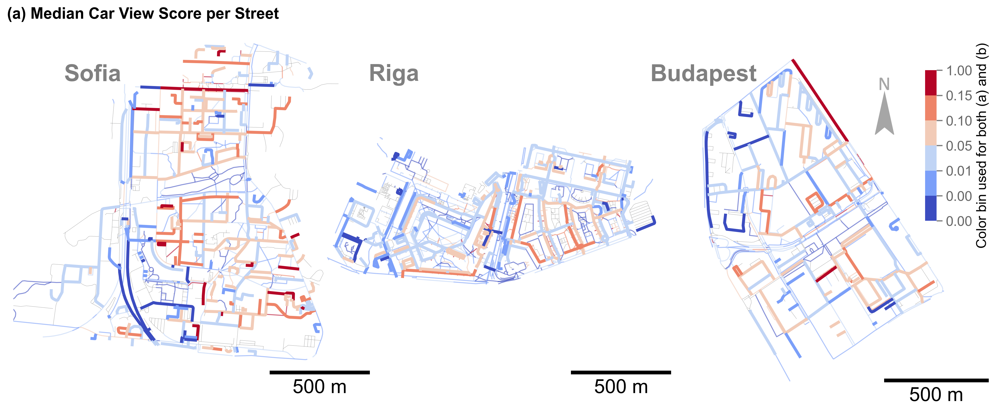

In [40]:
fig, axes = plt.subplots(1, 3, figsize=(18, 7), dpi=300)
fig.subplots_adjust(wspace=-0.2)
# Get legend handles from the first plot call
plot_street_median_svi(
    site_svi_with_category=sofia_svi_with_category,
    site_streets_in_site=sofia_streets_in_site,
    site='Sofia', define_bins=True,
    filter_functional_categories=['Residential / Slow-Speed Mixed', 'Shared Access / Local Mixed-Use'],
    differentiate_streets=True, no_legend=True, no_title=True, ax=axes[0]
)

# Plot the other two without returning legend handles
plot_street_median_svi(
    site_svi_with_category=riga_svi_with_category,
    site_streets_in_site=riga_streets_in_site,
    site='Riga', define_bins=True,
    filter_functional_categories=['Residential / Slow-Speed Mixed', 'Shared Access / Local Mixed-Use'],
    differentiate_streets=True, no_legend=True, no_title=True, ax=axes[1]
)

plot_street_median_svi(
    site_svi_with_category=budapest_svi_with_category,
    site_streets_in_site=budapest_streets_in_site,
    site='Budapest', define_bins=True,
    filter_functional_categories=['Residential / Slow-Speed Mixed', 'Shared Access / Local Mixed-Use'],
    differentiate_streets=True, no_title=True, set_labels=True, ax=axes[2]
)

for ax, title in zip(axes, titles):
    # Get the center of the axis in figure coordinates
    bbox = ax.get_position()
    x = bbox.x0 + bbox.width / 2 - 0.08
    fig.text(x, 0.77, title, ha='center', va='bottom',
             fontsize=24, fontweight='bold', color='grey')

# Add text at the top of the figure
fig.text(0.12, 0.9, "(a) Median Car View Score per Street",
         ha='left', va='bottom', fontsize=16, fontweight='bold',
         color='black')#, alpha=0.7)

# Add a image to the figure
img = plt.imread('north_arrow.png')
fig.figimage(img, 3700, 1200, zorder=1)# alpha=0.5,

# plt.tight_layout()
plt.show()

# Save as results_fig_02a.png
# fig.savefig('results_fig_02a.png', bbox_inches='tight', dpi=300,transparent=True, pad_inches=0)

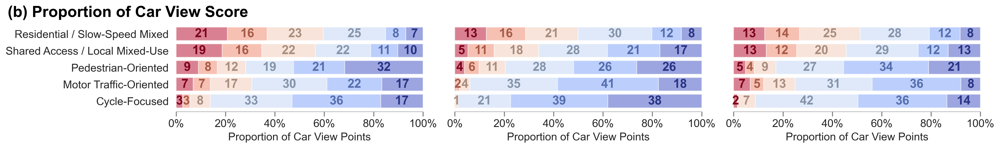

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(18, 2.5), dpi=300)
stacked_bar_plot(site_svi_with_category = sofia_svi_with_category, site='Sofia', label_factor=0.7, 
                 no_legend=True, no_title=True, figsize=(12,3), ax=axes[0])
stacked_bar_plot(site_svi_with_category = riga_svi_with_category, site='Riga', label_factor=0.7, 
                 no_legend=True, no_title=True,no_y_labels=True,figsize=(8.7,3), ax=axes[1])
stacked_bar_plot(site_svi_with_category = budapest_svi_with_category, site='Budapest', label_factor=0.7,
                 no_legend=True, no_title=True,no_y_labels=True,figsize=(8.7,3), ax=axes[2])
plt.tight_layout()
# Add text at the top of the figure
fig.text(0.012, 0.95, "(b) Proportion of Car View Score",
         ha='left', va='bottom', fontsize=20, fontweight='bold',
         color='black')#, alpha=0.7)
plt.show()
# Save as results_fig_02b.png